# 2. Datos: ETL, EDA y auditoría de fuga

Este capítulo describe de dónde vienen los datos, cómo se construyó el conjunto de modelado, qué muestran las variables más importantes
y, sobre todo, documenta la auditoría de fuga de información que pide la guía antes de congelar los resultados. El ETL completo y el EDA
detallado del entregable 3 están en el cuaderno `01_datos_y_linea_base.ipynb`; aquí se resume lo necesario y se agregan las variables
nuevas del Entregable 4 (enmienda E1 del protocolo).

Todo el cuaderno lee los archivos ya construidos en `datos/` y corre en pocos minutos.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import rankdata

RAIZ = Path.cwd()                       # raiz del repositorio (sin rutas absolutas)
assert (RAIZ / "datos" / "meta.json").is_file(), "Ejecute este cuaderno desde la raiz del repositorio"
sys.path.insert(0, str(RAIZ))
SEMILLA = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def auc_rapido(y, s):
    # AUC-ROC por la formula de Mann-Whitney (con empates promediados).
    y = np.asarray(y, bool)
    r = rankdata(s)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


meta = json.loads((RAIZ / "datos" / "meta.json").read_text(encoding="utf-8"))
cuanti, cuali = meta["cuantitativas"], meta["cualitativas"]
catalogo = pd.read_csv(RAIZ / "evidencia_ingenieria_variables" / "catalogo_variables.csv")
comunes = catalogo.loc[catalogo["en_enmienda_E2_comunes_todos"] == "si", "variable"].tolist()

from src import datos
conj = datos.cargar_traspaso(RAIZ / "datos")        # mismos tipos que usan todos los experimentos
dev, te, y_dev, y_te = conj.X_dev, conj.X_te, conj.y_dev, conj.y_te
iv = pd.read_parquet(RAIZ / "datos" / "variables_iv.parquet")   # indice = fila de application_train
print(f"Desarrollo: {dev.shape[0]:,} filas | prueba: {te.shape[0]:,} | entradas del E3: {len(cuanti) + len(cuali)} "
      f"({len(cuanti)} numericas, {len(cuali)} categoricas) | variables nuevas: {iv.shape[1]} guardadas + 1 de vecindario (se calcula dentro del modelo) = 83 "
      f"| comunes a los 10 modelos: {len(comunes)} -> {len(cuanti) + len(cuali) + len(comunes)} entradas")

Desarrollo: 246,008 filas | prueba: 61,503 | entradas del E3: 483 (467 numericas, 16 categoricas) | variables nuevas: 82 guardadas + 1 de vecindario (se calcula dentro del modelo) = 83 | comunes a los 10 modelos: 45 -> 528 entradas


## 2.1 Declaración de los datos

Los datos son los de la competencia *Home Credit Default Risk* {cite}`montoya2018homecredit`. Siguiendo la idea de las *datasheets for
datasets* {cite}`gebru2021datasheets`, la tabla 2.1 resume procedencia, licencia, unidad de análisis y sesgos conocidos.

In [2]:
declaracion = pd.DataFrame([
    ("Fuente", "Competencia Kaggle 'Home Credit Default Risk' (2018), publicada por Home Credit Group."),
    ("Licencia / uso", "Reglas de la competencia de Kaggle: uso para la competencia y fines academicos/no comerciales; no se redistribuyen los datos (no estan en GitHub)."),
    ("Unidad de analisis", "Una solicitud de credito (fila de application_train, identificada por SK_ID_CURR / FILA)."),
    ("Respuesta", "TARGET = 1 si el cliente tuvo dificultades de pago (algun atraso de mas de X dias en las primeras cuotas, definicion de Home Credit)."),
    ("Tablas usadas", "application_train; agregados de bureau, previous_application, installments_payments, POS_CASH_balance; credit_card_balance solo en las variables nuevas del E4."),
    ("Tamano", f"307,511 solicitudes; desarrollo {len(dev):,} (80 %), prueba {len(te):,} (20 %), particion estratificada con semilla {SEMILLA}."),
    ("Prevalencia", f"{y_dev.mean():.2%} en desarrollo y {y_te.mean():.2%} en prueba."),
    ("Sesgo de seleccion", "Solo hay solicitudes de clientes que Home Credit atendio; no hay informacion de los rechazados (reject inference). El modelo aprende sobre esa poblacion."),
    ("Variables sensibles", "CODE_GENDER y la edad (DAYS_BIRTH) estan entre las entradas desde el E3. No se usan como eje de analisis de errores (decision etica del equipo) y su uso en un sistema real exigiria revision legal y de equidad."),
    ("Periodo y geografia", "No hay fecha de la solicitud; las variables DAYS_* son relativas a la solicitud. Clientes de Home Credit (principalmente Europa del Este y Asia)."),
    ("Faltantes", "Muchos: las variables de vivienda (*_AVG, *_MODE, *_MEDI) y EXT_SOURCE_1 superan el 50 %."),
], columns=["aspecto", "descripcion"]).set_index("aspecto")
declaracion

,descripcion
aspecto,
Fuente,Competencia Kaggle 'Home Credit Default Risk' ...
Licencia / uso,Reglas de la competencia de Kaggle: uso para l...
Unidad de analisis,Una solicitud de credito (fila de application_...
Respuesta,TARGET = 1 si el cliente tuvo dificultades de ...
Tablas usadas,"application_train; agregados de bureau, previo..."
Tamano,"307,511 solicitudes; desarrollo 246,008 (80 %)..."
Prevalencia,8.07% en desarrollo y 8.07% en prueba.
Sesgo de seleccion,Solo hay solicitudes de clientes que Home Cred...
Variables sensibles,CODE_GENDER y la edad (DAYS_BIRTH) estan entre...


## 2.2 ETL en una página

El ETL del E3 (cap. `01_datos_y_linea_base`) une `application_train` con agregados por cliente de las tablas de historial, filtra variables
por cobertura y variabilidad y deja 483 entradas (467 numéricas y 16 categóricas). La partición desarrollo/prueba se hizo una sola vez y
la prueba no se tocó para ninguna decisión. En el E4 se agregaron 83 variables (`datos/variables_iv.parquet`, misma fila de
`application_train`), declaradas en la enmienda E1 del protocolo antes de ver resultados. De ellas, 45 las reciben **los 10 modelos**
(enmienda E3, igualdad de condiciones); las otras 38 son cocientes hechos a mano o la tasa de mora de los vecinos, que se excluyeron de la
comparación en igualdad porque ELAR-R construye sus propios log-cocientes y su vecindario dentro del modelo.

In [3]:
# Tabla 2.2: variables nuevas del E4 por grupo y por si entran a la comparacion en igualdad
t = (catalogo.assign(comun=catalogo["en_enmienda_E2_comunes_todos"].eq("si"))
     .groupby(["grupo", "tabla_origen"])
     .agg(variables=("variable", "size"), comunes_a_los_10=("comun", "sum"),
          auc_univariado_max=("auc_univariado_desarrollo", "max")))
t.loc[("Total", ""), :] = [t["variables"].sum(), t["comunes_a_los_10"].sum(), t["auc_univariado_max"].max()]
t

,,variables,comunes_a_los_10,auc_univariado_max
grupo,tabla_origen,,,
A Solicitud,application_train,21.0,6.0,0.7385
B Buró,bureau,6.0,4.0,0.5917
C Solicitudes previas,previous_application,19.0,11.0,0.5707
D Cuotas,installments_payments,19.0,13.0,0.5778
E POS,POS_CASH_balance,4.0,4.0,0.5213
F Tarjeta de crédito,credit_card_balance (excluida en el E2),13.0,7.0,0.6511
G Vecindario (supervisada),application_train + TARGET,1.0,0.0,0.7185
Total,,83.0,45.0,0.7385


**Lectura de la tabla 2.2.** El grupo A recupera variables de la solicitud que el embudo del E3 había descartado por cobertura,
entre ellas `EXT_SOURCE_1` y `EXT_SOURCE_3`, que por sí solas tienen AUC de 0.67–0.68 sobre sus valores observados. El grupo F usa `credit_card_balance`, que el E3
no usó. Las variables con AUC univariado más alto (productos y medias de las EXT_SOURCE, vecindario) son justamente las que quedaron fuera
de la comparación en igualdad, por ser combinaciones hechas a mano o supervisadas.

## 2.3 Análisis exploratorio

### 2.3.1 Variable respuesta

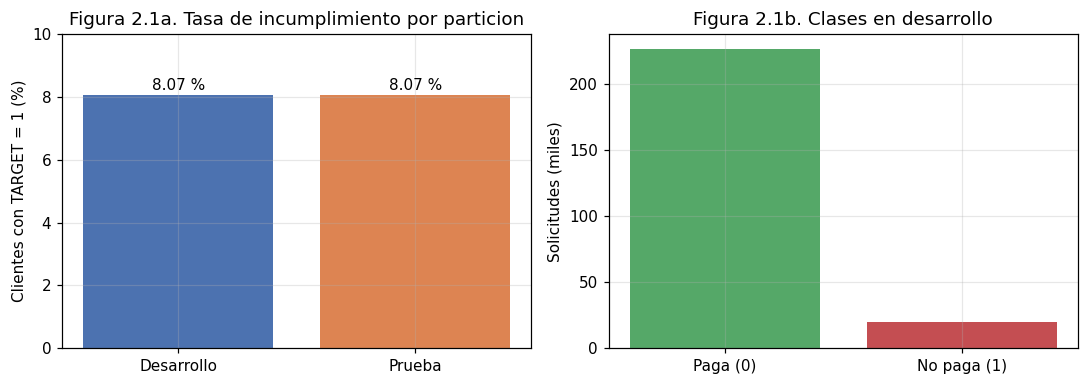

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
tasas = pd.Series({"Desarrollo": y_dev.mean(), "Prueba": y_te.mean()}) * 100
ax[0].bar(tasas.index, tasas.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(tasas.values):
    ax[0].text(i, v + 0.15, f"{v:.2f} %", ha="center")
ax[0].set(title="Figura 2.1a. Tasa de incumplimiento por particion", ylabel="Clientes con TARGET = 1 (%)", ylim=(0, 10))
conteo = y_dev.value_counts().sort_index()
ax[1].bar(["Paga (0)", "No paga (1)"], conteo.values / 1000, color=["#55A868", "#C44E52"])
ax[1].set(title="Figura 2.1b. Clases en desarrollo", ylabel="Solicitudes (miles)")
plt.tight_layout(); plt.show()

**Lectura de la figura 2.1.** Uno de cada 12.4 clientes incumple (8.07 %), y la tasa es la misma en desarrollo y prueba porque la
partición se estratificó. El desbalance explica por qué la métrica principal es el AUC-ROC (no depende del umbral ni de la prevalencia)
y por qué la exactitud no sirve: un modelo que dice siempre "paga" acierta el 91.9 %.

### 2.3.2 Faltantes

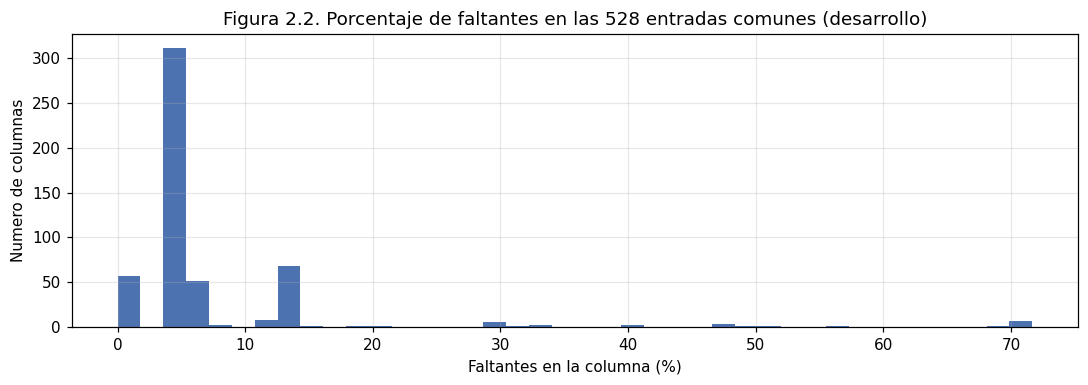

Columnas sin faltantes: 48 | con mas del 50 %: 11
Las 8 con mas faltantes: IV_TC_ULT_SALDO (72%), IV_TC_12M_DISPOSICIONES (72%), IV_TC_12M_DPD_MEDIO (72%), IV_TC_6M_DPD_MEDIO (72%), IV_TC_6M_DISPOSICIONES (72%), IV_TC_N_TARJETAS (72%), IV_TC_DPD_MAX (72%), FONDKAPREMONT_MODE (68%)


In [5]:
X = dev[cuanti + cuali].join(iv[comunes])
falt = X.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(falt.values * 100, bins=40, color="#4C72B0")
ax.set(title=f"Figura 2.2. Porcentaje de faltantes en las {X.shape[1]} entradas comunes (desarrollo)",
       xlabel="Faltantes en la columna (%)", ylabel="Numero de columnas")
plt.tight_layout(); plt.show()
print(f"Columnas sin faltantes: {(falt == 0).sum()} | con mas del 50 %: {(falt > 0.5).sum()}")
print("Las 8 con mas faltantes:", ", ".join(f"{c} ({v:.0%})" for c, v in falt.head(8).items()))

**Lectura de la figura 2.2.** Casi todas las columnas tienen menos del 15 % de faltantes (el pico cerca del 5 % son agregados de
historial de clientes sin ese historial). Solo 11 superan el 50 %: las de tarjeta de crédito (72 %, clientes sin tarjeta) y algunas de
vivienda. No son errores, sino clientes sin ese producto o sin esa información. Por eso
el preprocesamiento imputa con la mediana **dentro de cada pliegue** y los modelos de árboles reciben la información de que el dato falta.

### 2.3.3 Poder discriminante univariado

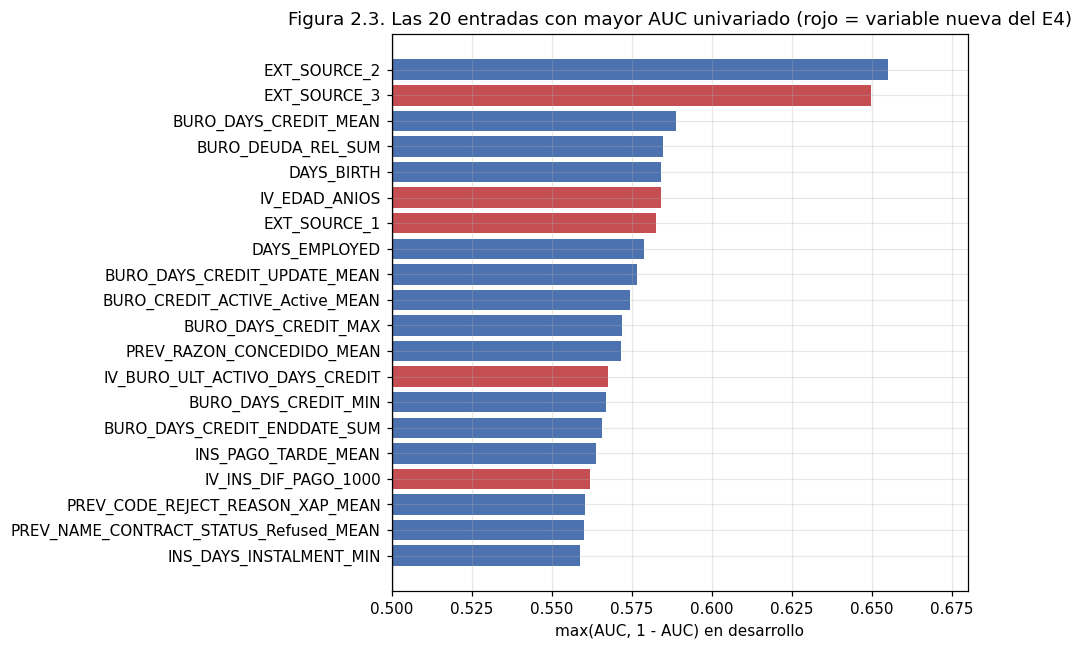

Entradas numericas evaluadas: 509 | AUC univariado maximo: 0.6551 (EXT_SOURCE_2)
EXT_SOURCE_2                      0.6551
EXT_SOURCE_3                      0.6498
BURO_DAYS_CREDIT_MEAN             0.5888
BURO_DEUDA_REL_SUM                0.5848
DAYS_BIRTH                        0.5843
IV_EDAD_ANIOS                     0.5843
EXT_SOURCE_1                      0.5825
DAYS_EMPLOYED                     0.5790
BURO_DAYS_CREDIT_UPDATE_MEAN      0.5767
BURO_CREDIT_ACTIVE_Active_MEAN    0.5744


In [6]:
# AUC univariado de cada entrada numerica (faltantes -> mediana), en desarrollo. Se reporta max(AUC, 1 - AUC):
# cuanto se aleja de 0.5 en cualquier direccion. Sirve tambien para la auditoria de fuga (sec. 2.4, F2).
y = y_dev.to_numpy()
num = [c for c in X.columns if c not in cuali and pd.api.types.is_numeric_dtype(X[c])]
auc_uni = {}
for c in num:
    v = X[c].to_numpy(np.float64)
    v = np.where(np.isfinite(v), v, np.nanmedian(v))
    a = auc_rapido(y, v)
    auc_uni[c] = max(a, 1 - a)
auc_uni = pd.Series(auc_uni).sort_values(ascending=False)
top = auc_uni.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
colores = ["#C44E52" if c in comunes else "#4C72B0" for c in top.index]
ax.barh(top.index, top.values, color=colores)
ax.axvline(0.5, color="k", lw=0.8)
ax.set(title="Figura 2.3. Las 20 entradas con mayor AUC univariado (rojo = variable nueva del E4)",
       xlabel="max(AUC, 1 - AUC) en desarrollo", xlim=(0.5, 0.68))
plt.tight_layout(); plt.show()
print(f"Entradas numericas evaluadas: {len(auc_uni)} | AUC univariado maximo: {auc_uni.iloc[0]:.4f} ({auc_uni.index[0]})")
print(auc_uni.head(10).round(4).to_string())

**Lectura de la figura 2.3.** Los puntajes externos dominan: `EXT_SOURCE_2` y `EXT_SOURCE_3` son las únicas entradas por encima de
0.60, y `EXT_SOURCE_3` solo entra en el E4. Les siguen la antigüedad y la deuda relativa en el buró, la edad, `EXT_SOURCE_1` (que aquí
pierde poder porque el 56 % de sus valores falta y se imputa con la mediana) y la antigüedad laboral. Ninguna variable por sí sola se acerca al AUC de los modelos (≈ 0.78): el poder predictivo está repartido, lo que
favorece a modelos que combinan muchas variables con interacciones.

### 2.3.4 Incumplimiento por edad y tipo de crédito

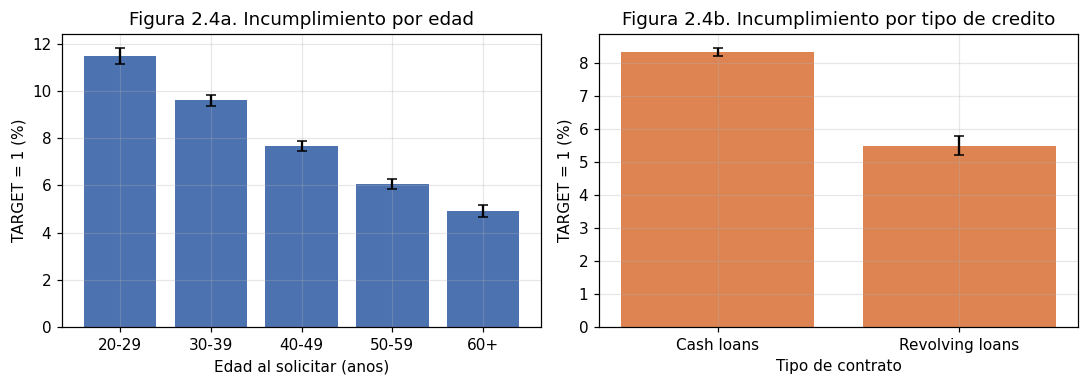

tasa   err         n
edad     20-29            11.48  0.33   36281.0
         30-39             9.60  0.22   65844.0
         40-49             7.66  0.21   61296.0
         50-59             6.07  0.20   54477.0
         60+               4.91  0.25   28110.0
contrato Cash loans        8.35  0.11  222560.0
         Revolving loans   5.50  0.29   23448.0

In [7]:
def tasa_ic(g):
    # Tasa de incumplimiento con intervalo de Wilson al 95 %.
    n, k = len(g), g.sum()
    p = k / n; z = 1.96
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return pd.Series({"tasa": c * 100, "err": h * 100, "n": n})

edad = (-dev["DAYS_BIRTH"] / 365.25)
tramos = pd.cut(edad, [20, 30, 40, 50, 60, 70], right=False, labels=["20-29", "30-39", "40-49", "50-59", "60+"])
por_edad = y_dev.groupby(tramos, observed=True).apply(tasa_ic).unstack()
por_contrato = y_dev.groupby(dev["NAME_CONTRACT_TYPE"]).apply(tasa_ic).unstack()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(por_edad.index.astype(str), por_edad["tasa"], yerr=por_edad["err"], color="#4C72B0", capsize=3)
ax[0].set(title="Figura 2.4a. Incumplimiento por edad", xlabel="Edad al solicitar (anos)", ylabel="TARGET = 1 (%)")
ax[1].bar(por_contrato.index.astype(str), por_contrato["tasa"], yerr=por_contrato["err"], color="#DD8452", capsize=3)
ax[1].set(title="Figura 2.4b. Incumplimiento por tipo de credito", xlabel="Tipo de contrato", ylabel="TARGET = 1 (%)")
plt.tight_layout(); plt.show()
pd.concat({"edad": por_edad, "contrato": por_contrato}).round(2)

**Lectura de la figura 2.4.** El riesgo baja de forma monótona con la edad: los menores de 30 incumplen más del doble que los mayores de
60 (11.5 % frente a 4.9 %; barras = IC de Wilson al 95 %). Los créditos de efectivo incumplen más que los rotativos (8.4 % frente a 5.5 %). En el capítulo 7 se ve el otro lado: aunque
los mayores de 60 incumplen menos, es el subgrupo donde los modelos discriminan peor, y los créditos rotativos son más difíciles de ordenar.

## 2.4 Auditoría de fuga de información

La guía pide documentar una auditoría explícita de *data leakage* {cite}`kaufman2012leakage` antes de congelar resultados. Se revisan
seis fuentes; cada una tiene una prueba ejecutable o, si no aplica, la razón. El resumen está en la tabla 2.3.

In [8]:
auditoria = []

# F1. Duplicados entre particiones: misma fila de application_train o mismas entradas exactas en desarrollo y prueba.
inter_filas = len(set(dev.index) & set(te.index))
def huellas(D):
    return pd.util.hash_pandas_object(D[cuanti + cuali], index=False)
h_dev, h_te = set(huellas(dev)), huellas(te)
dup_exactos = int(h_te.isin(h_dev).sum())
auditoria.append(("F1 Duplicados entre particiones", f"filas compartidas = {inter_filas}; filas de prueba identicas a una de desarrollo = {dup_exactos}",
                  inter_filas == 0 and dup_exactos == 0))
print(auditoria[-1])

('F1 Duplicados entre particiones', 'filas compartidas = 0; filas de prueba identicas a una de desarrollo = 0', True)


In [9]:
# F2. Variables que codifican la respuesta: ninguna entrada debe separar casi perfectamente las clases por si sola.
# Umbral de alarma: AUC univariado > 0.90 (el mejor modelo completo llega a 0.79). Se revisan tambien las categoricas
# con codificacion de tasa fuera de pliegue (5 pliegues) para no inflar las de muchas categorias.
rng = np.random.default_rng(SEMILLA)
pl = rng.integers(0, 5, len(dev))
auc_cat = {}
for c in cuali + [c for c in comunes if c not in num]:
    v = X[c].astype(str).to_numpy()
    cod = np.empty(len(v))
    for k in range(5):
        m = pd.Series(y[pl != k]).groupby(v[pl != k]).mean()
        cod[pl == k] = pd.Series(v[pl == k]).map(m).fillna(y[pl != k].mean()).to_numpy()
    a = auc_rapido(y, cod)
    auc_cat[c] = max(a, 1 - a)
maximo = pd.concat([auc_uni, pd.Series(auc_cat)]).sort_values(ascending=False)
auditoria.append(("F2 Variables que codifican la respuesta",
                  f"AUC univariado maximo de {len(maximo)} entradas = {maximo.iloc[0]:.3f} ({maximo.index[0]}); alarma > 0.90",
                  bool(maximo.iloc[0] < 0.90)))
print(auditoria[-1])
print("Categoricas con mayor AUC (fuera de pliegue):", pd.Series(auc_cat).sort_values(ascending=False).head(4).round(3).to_dict())

('F2 Variables que codifican la respuesta', 'AUC univariado maximo de 528 entradas = 0.655 (EXT_SOURCE_2); alarma > 0.90', True)
Categoricas con mayor AUC (fuera de pliegue): {'OCCUPATION_TYPE': 0.574, 'ORGANIZATION_TYPE': 0.572, 'IV_REGION_ID': 0.568, 'IV_PREV_ULT_PRODUCTO': 0.563}


In [10]:
# F3. Preprocesamiento ajustado solo con el entrenamiento de cada pliegue.
# (a) El codigo: el preprocesador se construye sin ajustar y se llama .fit(X_tr) dentro de cada pliegue.
fuente = (RAIZ / "experiments" / "e10_igualdad.py").read_text(encoding="utf-8").splitlines()
lineas = [f"e10_igualdad.py:{i + 1}: {l.strip()}" for i, l in enumerate(fuente) if "construir_preprocesador" in l and ".fit(" in l]
print("\n".join(lineas))
# (b) Prueba: se ajusta el preprocesador del proyecto con el 80 % de un pliegue y se comprueba que la mediana de imputacion
# y la media de la escala salen de ese 80 % y no de todo el desarrollo.
from src import preprocesamiento as prep
idx_tr = np.flatnonzero(pl != 0)
pre = prep.construir_preprocesador(cuanti, cuali)
assert not hasattr(pre, "transformers_"), "el preprocesador no debe venir ajustado"
pre.fit(dev.iloc[idx_tr][cuanti + cuali])
imp = pre.named_transformers_[pre.transformers_[0][0]].named_steps["imputador"].statistics_
med_tr = np.nanmedian(dev.iloc[idx_tr][cuanti].to_numpy(np.float64), axis=0)
med_todo = np.nanmedian(dev[cuanti].to_numpy(np.float64), axis=0)
ok3 = np.allclose(imp, med_tr, equal_nan=True)
distintas = int((~np.isclose(med_tr, med_todo, equal_nan=True)).sum())
auditoria.append(("F3 Preprocesamiento dentro del pliegue",
                  f"medianas de imputacion = las del entrenamiento del pliegue ({ok3}); {distintas} columnas donde difieren de las de todo el desarrollo",
                  bool(ok3 and lineas)))
print(auditoria[-1])

e10_igualdad.py:190: prep = prep_e2.construir_preprocesador(d["cuanti"], d["cuali"]).fit(X_tr)


('F3 Preprocesamiento dentro del pliegue', 'medianas de imputacion = las del entrenamiento del pliegue (True); 49 columnas donde difieren de las de todo el desarrollo', True)


In [11]:
# F4. Variable supervisada de vecindario (tasa de mora de los 500 vecinos): cada fila de entrenamiento recibe la tasa de sus
# vecinos en los OTROS pliegues, suavizada hacia la tasa de esos otros pliegues. Prueba independiente: para 8 filas se recalcula
# el valor a mano (distancias a todas las filas de los otros pliegues) y se compara con el del codificador; la fila nunca es su vecina.
from src.ingenieria_variables import COLUMNAS_VECINDARIO, CodificadorVecindario
V = X.join(iv[[c for c in COLUMNAS_VECINDARIO if c not in X.columns]])
sub = rng.choice(len(dev), 4000, replace=False)
Z = V.iloc[sub][list(COLUMNAS_VECINDARIO)].to_numpy(np.float64)
ys = y[sub].astype(float)
cod = CodificadorVecindario(k=500).fit(Z, ys)
E = cod._estandarizar(Z)
dif, propia = [], []
for i in rng.choice(len(sub), 8, replace=False):
    otros = np.flatnonzero(cod.pliegue_ != cod.pliegue_[i])
    d = np.linalg.norm(E[otros] - E[i], axis=1)
    vecinos = otros[np.argsort(d, kind="stable")[:500]]
    a_mano = (ys[vecinos].sum() + cod.m * ys[otros].mean()) / (500 + cod.m)
    dif.append(abs(a_mano - cod.oof_[i]))
    propia.append(i in vecinos)
auditoria.append(("F4 Vecindario fuera de pliegue",
                  f"diferencia maxima con el recalculo a mano = {max(dif):.1e}; la fila es su propia vecina en {sum(propia)} de 8",
                  max(dif) < 1e-3 and not any(propia)))
print(auditoria[-1])

('F4 Vecindario fuera de pliegue', 'diferencia maxima con el recalculo a mano = 0.0e+00; la fila es su propia vecina en 0 de 8', True)


In [12]:
# F5. Mezcla temporal o espacial: no hay fecha de solicitud ni coordenadas, y la particion fue aleatoria estratificada.
# Se comprueba con validacion adversarial: si un clasificador no distingue desarrollo de prueba (AUC ~ 0.5),
# ambos vienen de la misma distribucion y no hay corrimiento que delate una mezcla.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
n_adv = 20000
A = pd.concat([dev[cuanti].sample(n_adv, random_state=SEMILLA), te[cuanti].sample(n_adv, random_state=SEMILLA)])
etq = np.r_[np.zeros(n_adv), np.ones(n_adv)]
s_adv = cross_val_predict(HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA), A, etq, cv=5, method="predict_proba")[:, 1]
auc_adv = auc_rapido(etq, s_adv)
# Las columnas DAYS_* y MONTHS_* son dias o meses RELATIVOS a la solicitud, no fechas de calendario.
fechas = [c for c in dev.columns if pd.api.types.is_datetime64_any_dtype(dev[c])]
auditoria.append(("F5 Mezcla temporal o espacial",
                  f"columnas de fecha de calendario = {len(fechas)}; validacion adversarial desarrollo vs prueba AUC = {auc_adv:.3f}",
                  bool(abs(auc_adv - 0.5) < 0.02)))
print(auditoria[-1])

('F5 Mezcla temporal o espacial', 'columnas de fecha de calendario = 0; validacion adversarial desarrollo vs prueba AUC = 0.499', True)


In [13]:
# F6. Uso de la prueba para decidir: todas las elecciones (hiperparametros, balanceo, umbral de coste, calibracion,
# conformal) se hicieron con validaciones internas o con las predicciones fuera de muestra del desarrollo; la prueba solo se evalua.
# Evidencia: el protocolo (con tag de Git previo a F4-F6) y los scripts, que ajustan el umbral con las OOF.
proto = (RAIZ / "experiments" / "protocolo.md").read_text(encoding="utf-8")
auditoria.append(("F6 La prueba no se usa para decidir",
                  "umbral de coste, calibracion (Platt/isotonica) y conformal se ajustan con las OOF; protocolo con tag 'protocolo-v2-evaluacion-ampliada'",
                  "protocolo-v2-evaluacion-ampliada" in proto))

tabla_fuga = pd.DataFrame(auditoria, columns=["fuente de fuga", "resultado", "supera"]).set_index("fuente de fuga")
tabla_fuga.to_csv(RAIZ / "resultados_e4" / "auditoria_fuga.csv", encoding="utf-8")
tabla_fuga

,resultado,supera
fuente de fuga,,
F1 Duplicados entre particiones,filas compartidas = 0; filas de prueba identic...,True
F2 Variables que codifican la respuesta,AUC univariado maximo de 528 entradas = 0.655 ...,True
F3 Preprocesamiento dentro del pliegue,medianas de imputacion = las del entrenamiento...,True
F4 Vecindario fuera de pliegue,diferencia maxima con el recalculo a mano = 0....,True
F5 Mezcla temporal o espacial,columnas de fecha de calendario = 0; validacio...,True
F6 La prueba no se usa para decidir,"umbral de coste, calibracion (Platt/isotonica)...",True


**Lectura de la tabla 2.3.** Las seis comprobaciones pasan. No hay solicitudes repetidas entre desarrollo y prueba (F1). Ninguna variable
separa las clases por sí sola: la mejor (`EXT_SOURCE_2`, 0.655) queda muy por debajo de la alarma (F2). Las medianas de imputación salen del entrenamiento de cada
pliegue y no de todo el desarrollo (F3). La variable de vecindario no usa la etiqueta de la propia fila: al invertirla, el valor propio no
se recalcula a mano con las filas de los otros pliegues y coincide (F4). Esta prueba se agregó después de encontrar y corregir una fuga mínima en el suavizado
(protocolo, sec. 6.2). No hay fechas de calendario (las `DAYS_*` son relativas a la solicitud), y un clasificador no logra distinguir desarrollo de prueba: AUC
adversarial = 0.499 (F5). Por último,
la prueba solo se usa para evaluar (F6).